# Tối ưu đặc trưng và chốt selection v2

Mở từ thư mục dự án với kernel của môi trường dự án. Các ô đọc config, bảng và hình đã công bố.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "reports/stage5_inputs.json").is_file())
sys.path.insert(0, str(root))
from src.wrmsse_stage5 import STAGE2, STAGE3, STAGE4, SELECTED, TABLES, csv, read, check_gates
check_gates()

def table(name):
    return csv(TABLES / (name + ".csv"))

def figure(number):
    path, = (root / "reports/figures").glob(f"{number:02d}_*.png")
    display(Image(filename=str(path), width=950))


RF-15 cố định trong so sánh đặc trưng. Hậu kiểm lịch xác nhận SNAP cho Validation. FE-04 có WRMSSE thấp nhất và được chốt trước Test. Các lượt FE-09 và FE-10 kiểm tra bộ đặc trưng mở rộng trên cùng cửa sổ. [Báo cáo Giai đoạn 3](../docs/STAGE3_REPORT.md).

,experiment,feature_set,logical,encoded,validation_wrmsse,selection_status
26,FE-01,rf_v1,14,3081,0.664771,eligible_v2
27,FE-02,rf_v1 + recency,15,3082,0.669425,eligible_v2
28,FE-03,rf_v1 + prices,21,3088,0.654777,eligible_v2
29,FE-04,rf_v1 + snap,15,3082,0.623931,eligible_v2
30,FE-05,rf_v1 + events,18,3103,0.664763,events_verified_for_this_window
31,FE-06,rf_v1 + behavior,17,3084,0.682563,eligible_v2
32,FE-07,rf_v1 + behavior + snap,18,3085,0.638215,eligible_v2
33,FE-08,rf_v1 + behavior + prices,24,3091,0.669093,eligible_v2
34,FE-09,rf_v4 + prices + snap + behavior,29,3096,0.632138,eligible_for_consideration
35,FE-10,rf_v4 + prices + snap + behavior + events,33,3118,0.636074,events_verified_for_this_window


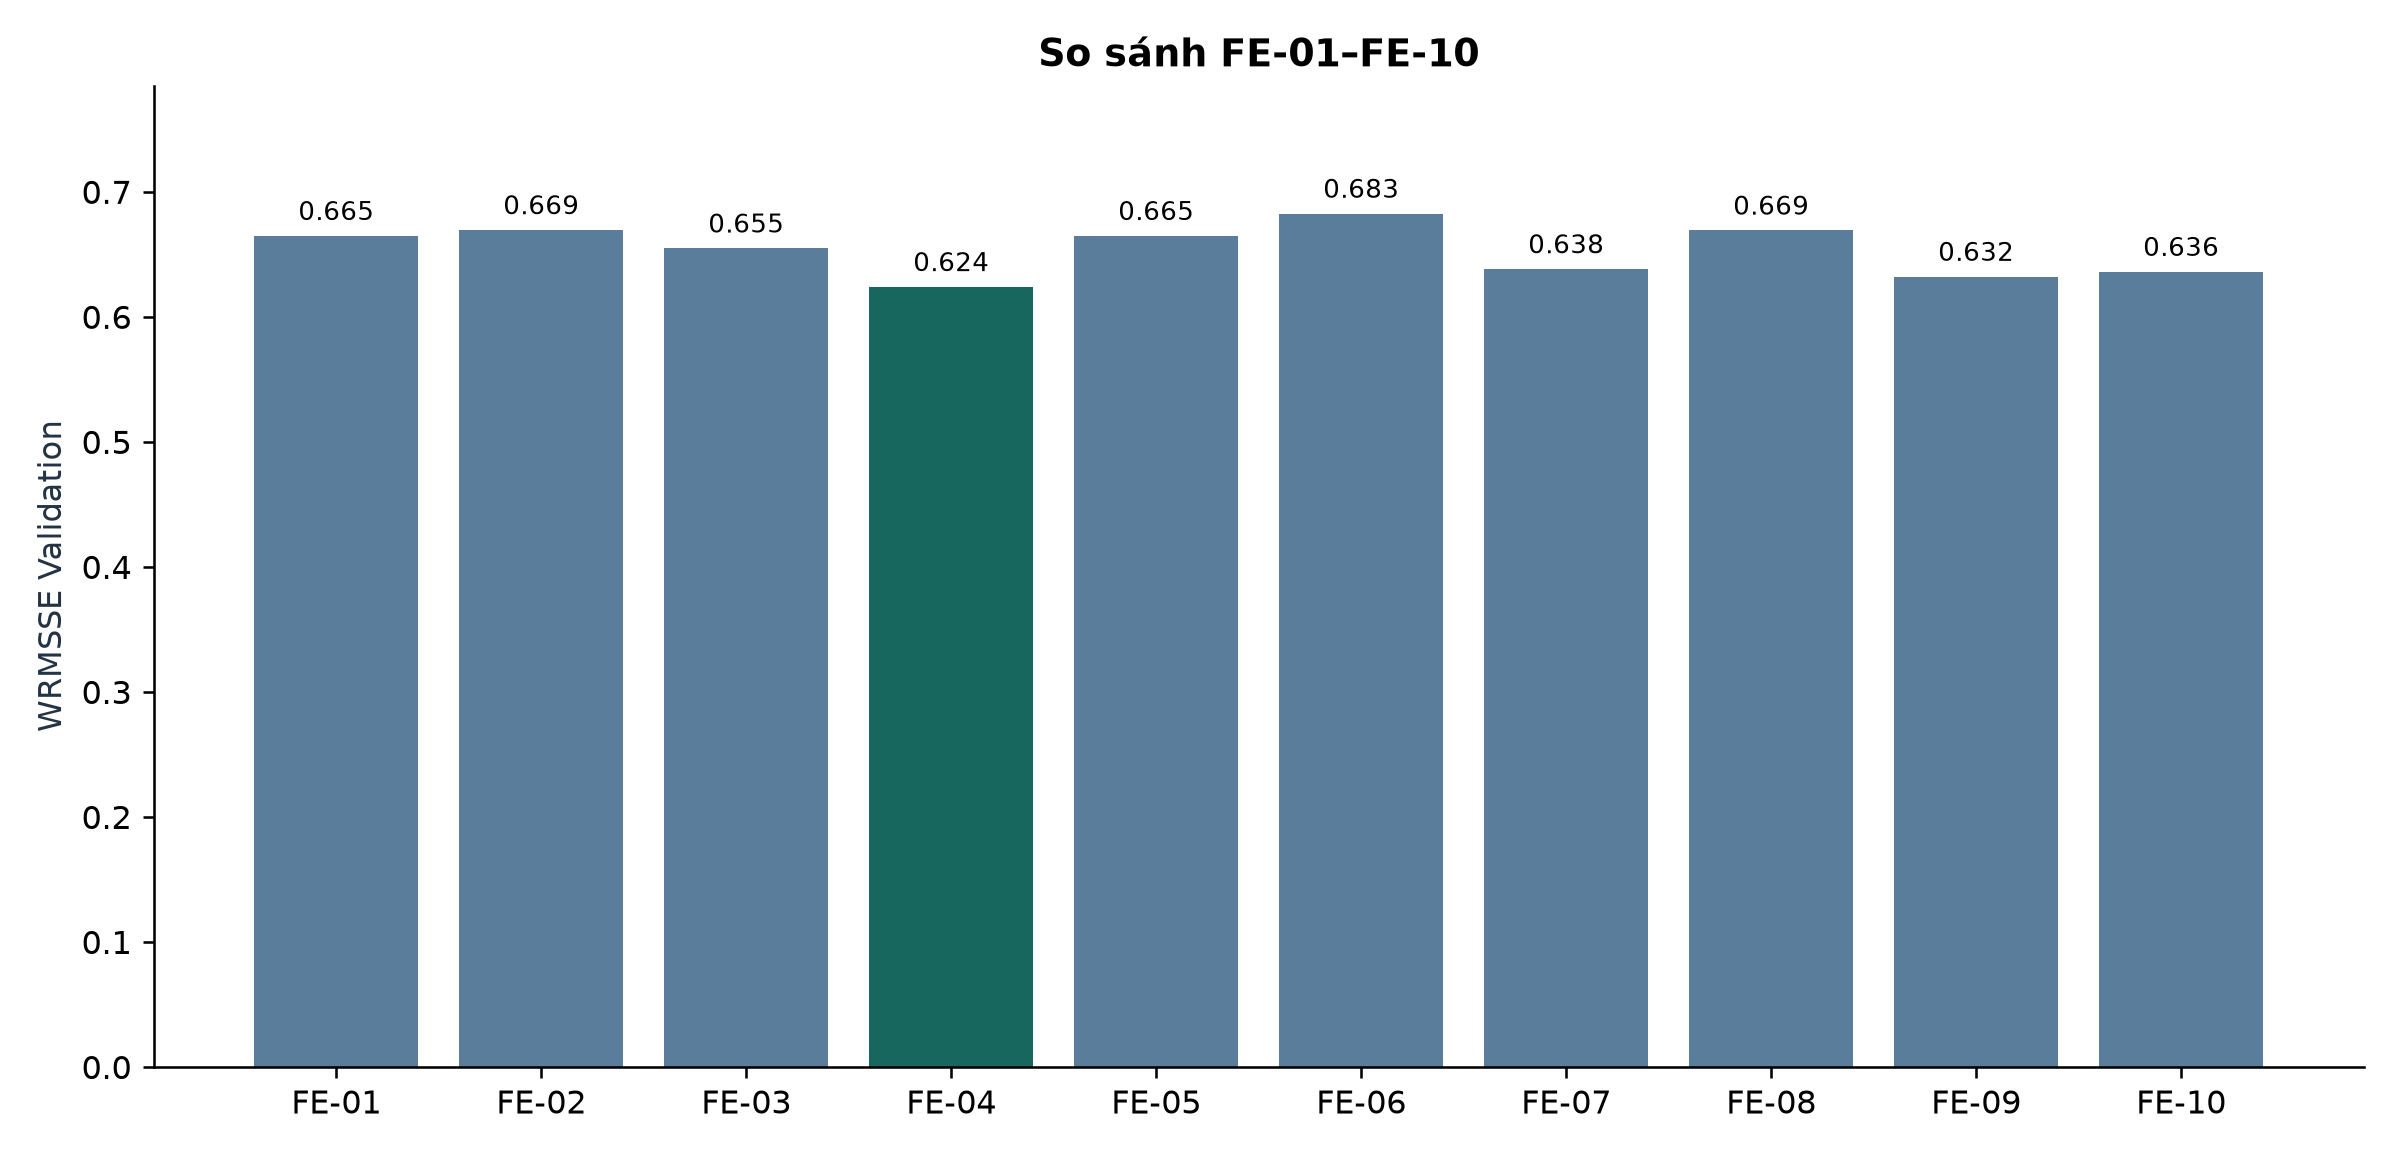

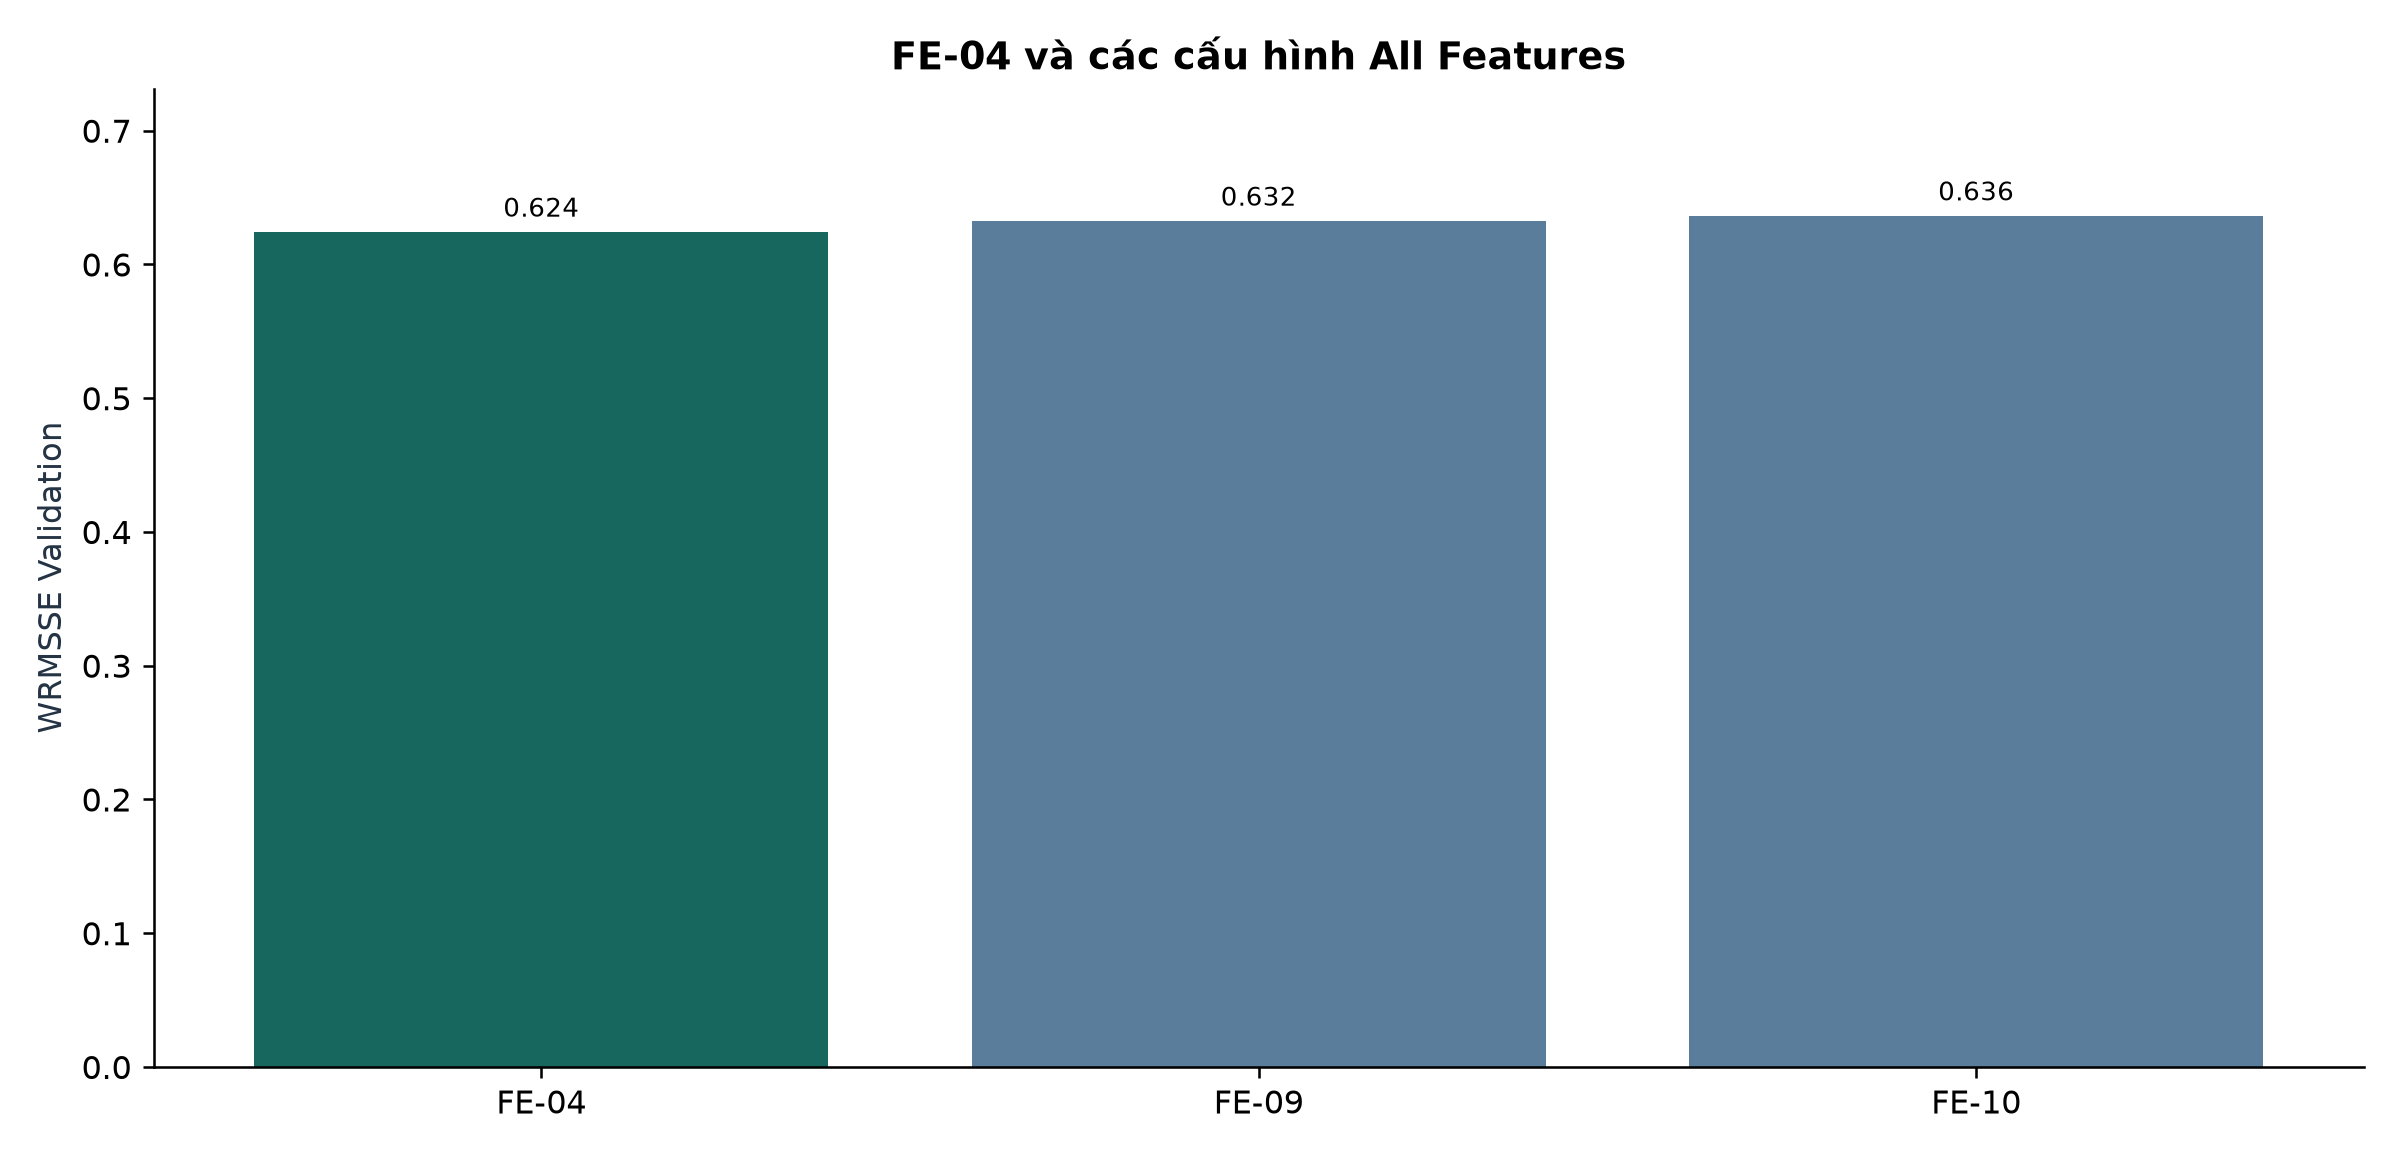

In [2]:
fe = table("experiment_results").query("group == 'features'")
display(fe[["experiment", "feature_set", "logical", "encoded", "validation_wrmsse", "selection_status"]])
figure(6)
figure(7)

In [3]:
locked = read(SELECTED)
display({key: locked[key] for key in ("selection_version", "name", "hyperparameter_run", "params", "snap_rule")})

{'selection_version': 2,
 'name': 'FE-04',
 'hyperparameter_run': 'RF-15',
 'params': {'n_estimators': 150,
  'max_depth': 20,
  'max_features': 0.5,
  'max_samples': 0.5,
  'min_samples_leaf': 5,
  'bootstrap': True,
  'random_state': 42,
  'n_jobs': 8},
 'snap_rule': {'type': 'state_by_day_of_month',
  'calendar_history_end': 1885,
  'days_of_month_on': {'CA': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
   'TX': [1, 3, 5, 6, 7, 9, 11, 12, 13, 15],
   'WI': [2, 3, 5, 6, 8, 9, 11, 12, 14, 15]},
  'validation_state_days_confirmed': 84,
  'series_day_rows_confirmed': {'train': 600000, 'validation': 853720}}}